# Dataset description
## Rate of thefts to people per 100k inhabitants

**Source thefts**: [MinDefensa](https://www.datos.gov.co/Seguridad-y-Defensa/HURTO-PERSONAS/4rxi-8m8d/about_data)

**Source Population**: [DANE](https://www.dane.gov.co/index.php/estadisticas-por-tema/demografia-y-poblacion/proyecciones-de-poblacion)

# Code
## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from highlight_text import fig_text
from pathlib import Path
import json

BASE_DIR = Path.cwd().parent.parent

## Load data

In [2]:
path = "./data/HURTO_PERSONAS_20261023.csv"

pop_path = "./data/departamental.csv"

df = pd.read_csv(
    path, encoding="utf-8",
    usecols=[0, 1, 5],
    na_values={"COD_DEPTO": "SIN ESTABLECER"},
    dtype={"COD_DEPTO": "Int32"},
    parse_dates=["FECHA HECHO"],
    dayfirst=True,
)

pop = pd.read_csv(pop_path, encoding="utf-8", usecols=[0, 1, 2, 308])

logo = plt.imread(BASE_DIR / "logo/logo.png")
with open("./data/colombia_departments.geojson", encoding="utf-8") as f:
    geo = json.load(f)

## Clean data

In [3]:
monthly = df[df["FECHA HECHO"].dt.month <= 9]
yearly = monthly.groupby(
    [monthly["FECHA HECHO"].dt.year, monthly["COD_DEPTO"]]
)["CANTIDAD"].sum().reset_index()

In [4]:
total = pd.merge(
    yearly, pop, left_on=["FECHA HECHO", "COD_DEPTO"], right_on=["AÑO", "DP"], how="left"
).drop(columns=["DP", "AÑO"])

In [5]:
cols = list(total.columns)
cols.insert(2, cols.pop(cols.index("DPNOM")))
total = total[cols]

In [6]:
total["Ratio"] = (total["CANTIDAD"] / total["Total"]) * 100000

In [7]:
def add_year_totals(df, year_col="FECHA HECHO", fill=None):
    fill = fill or {}
    pieces = []
    for year, group in df.groupby(year_col, sort=False):
        pieces.append(group)

        cantidad = group["CANTIDAD"].sum()
        total = group["Total"].sum()

        row = {col: fill.get(col, "") for col in df.columns}
        row[year_col] = year
        row["CANTIDAD"] = cantidad
        row["Total"] = total
        row["Ratio"] = cantidad / total * 100000

        pieces.append(pd.DataFrame([row]))

    return pd.concat(pieces, ignore_index=True)

total = add_year_totals(
    total,
    fill={"COD_DEPTO": "00", "DPNOM": "Total National"},
)

## Plot

In [8]:
background = "#F4F1EA"

# 2008 is dropped: most of its records have no department.
years = [y for y in range(2003, 2027) if y != 2008]

out_dir = Path.home() / "Pictures/Screenshots"

is_nat = total["DPNOM"] == "Total National"
depts = total[~is_nat].copy()
depts["DPTO"] = depts["COD_DEPTO"].astype(int).astype(str).str.zfill(2)
dept_rates = {y: g.set_index("DPTO")["Ratio"] for y, g in depts.groupby("FECHA HECHO")}
national_rates = total[is_nat].set_index("FECHA HECHO")["Ratio"]

# Shared scale so every year's map is directly comparable.
vmax = max(s.max() for s in dept_rates.values())

In [9]:
cmap = cm.Reds
norm = Normalize(vmin=0, vmax=vmax)
missing_color = "#D3D3D3"

sanandres_box = {"lon": (-79.0, -75.9), "lat": (10.9, 13.3)}


def exterior_rings(geometry: dict) -> list:
    if geometry["type"] == "Polygon":
        return [geometry["coordinates"][0]]
    return [poly[0] for poly in geometry["coordinates"]]


def bbox_area(ring: list) -> float:
    xs = [x for x, _ in ring]
    ys = [y for _, y in ring]
    return (max(xs) - min(xs)) * (max(ys) - min(ys))


def fit_box(rings: list, box: dict) -> list:
    """Uniform scale + center rings into a target lon/lat box (preserve aspect)."""
    xs = [x for r in rings for x, _ in r]
    ys = [y for r in rings for _, y in r]
    x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
    bx0, bx1 = box["lon"]
    by0, by1 = box["lat"]
    scale = min((bx1 - bx0) / (x1 - x0), (by1 - by0) / (y1 - y0))
    ox = bx0 + ((bx1 - bx0) - (x1 - x0) * scale) / 2
    oy = by0 + ((by1 - by0) - (y1 - y0) * scale) / 2
    return [[(ox + (x - x0) * scale, oy + (y - y0) * scale) for x, y in r]
            for r in rings]


def plot_rate_map(rates: pd.Series, national: float, year: int):
    fig, ax = plt.subplots(figsize=(10.8, 13.5), dpi=500)
    fig.patch.set_facecolor(background)
    ax.patch.set_facecolor(background)

    patches, colors = [], []
    for feat in geo["features"]:
        code = feat["properties"]["DPTO"]
        val = rates.get(code)
        color = missing_color if pd.isna(val) else cmap(norm(val))
        rings = exterior_rings(feat["geometry"])
        if code == "88":
            rings = fit_box([max(rings, key=bbox_area)], sanandres_box)
        for ring in rings:
            patches.append(Polygon(ring, closed=True))
            colors.append(color)

    ax.add_collection(PatchCollection(
        patches, facecolor=colors, edgecolor="white", linewidth=0.4))
    ax.autoscale_view()
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_position([0.03, 0.10, 0.78, 0.74])

    ax.text(-77.45, 10.6, "San Andrés", fontsize=8, color="gray",
            ha="center", va="top")

    fig_text(
        x=0.06, y=0.95,
        s=f"Theft rate to people by department · <{year}>",
        highlight_textprops=[{"color": cmap(0.85), "weight": "bold"}],
        fontsize=18,
    )
    fig_text(
        x=0.06, y=0.92,
        s="per 100,000 inhabitants · data for Jan-Sep of each year",
        fontsize=11, color="gray",
    )

    fig_text(
        x=0.60, y=0.88,
        s=f"<{national:.0f}>\nNational rate · per 100k",
        highlight_textprops=[{"color": cmap(0.85), "weight": "bold", "fontsize": 32}],
        fontsize=11, color="gray",
    )

    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    cax = fig.add_axes([0.87, 0.3, 0.025, 0.4])
    cbar = fig.colorbar(sm, cax=cax)
    cbar.set_label("Thefts to people per 100,000", fontsize=9, color="gray")
    cbar.ax.tick_params(labelsize=9, colors="gray")
    cbar.outline.set_visible(False)

    fig.text(
        0.06, 0.04,
        "Source: Ministerio de Defensa Nacional, DANE.",
        fontsize=9, color="gray")

    imagebox = OffsetImage(logo, zoom=0.4)
    ab = AnnotationBbox(imagebox, xy=(0.85, 0.045), xycoords="figure fraction",
                        frameon=False, pad=0)
    fig.add_artist(ab)

    plt.show()
    plt.close(fig)

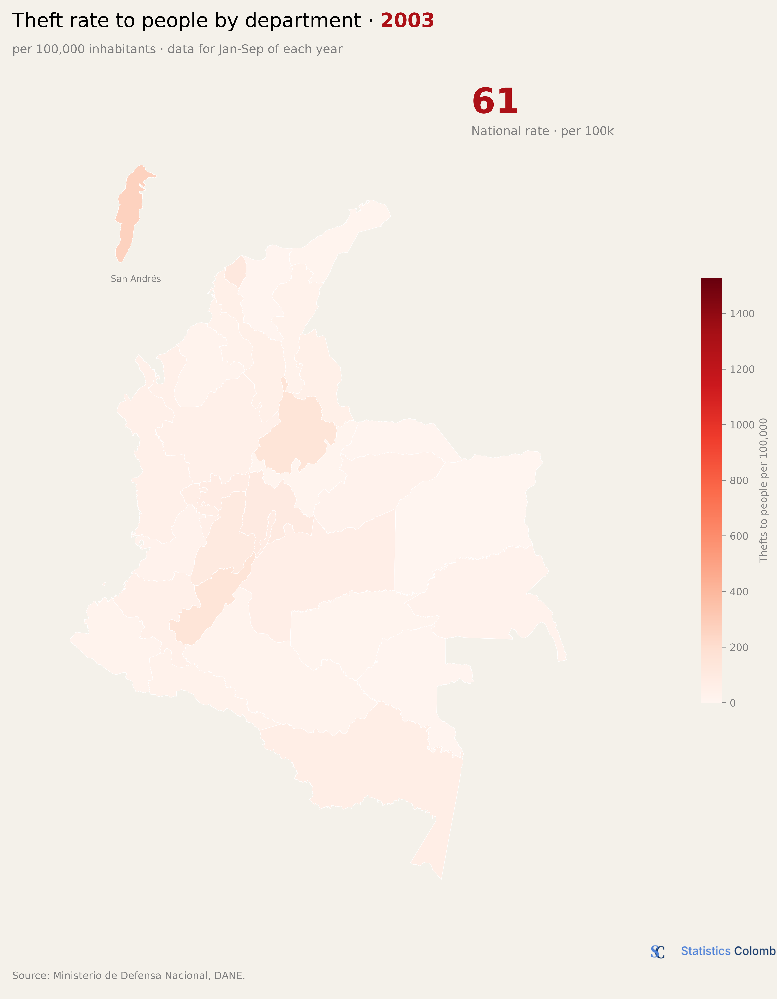

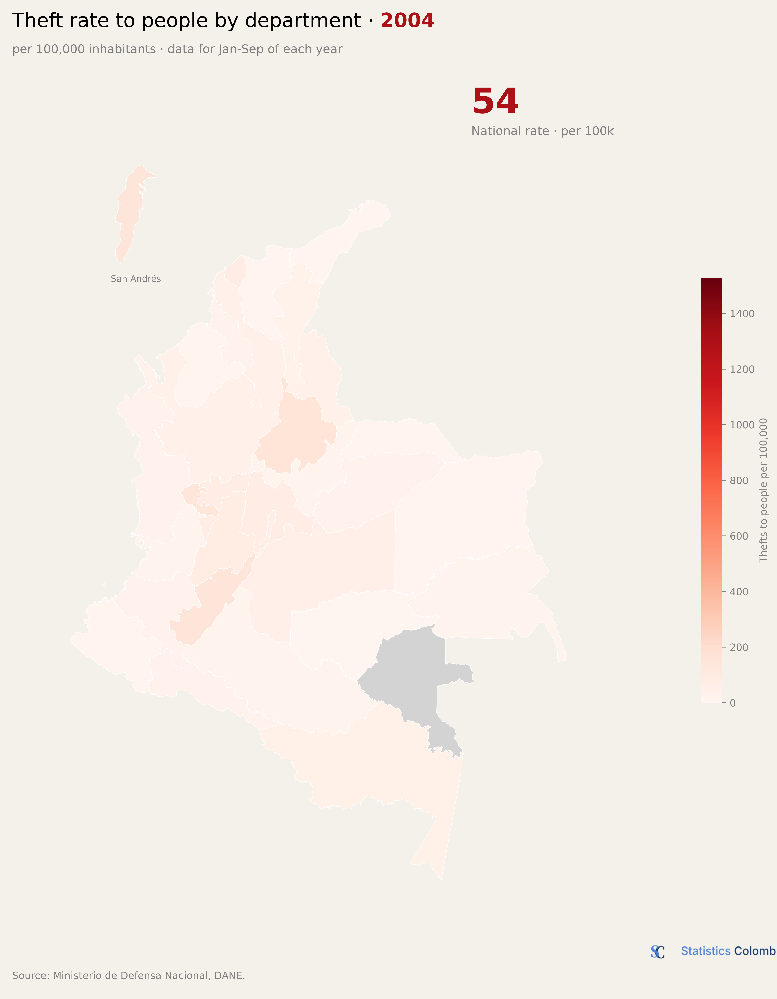

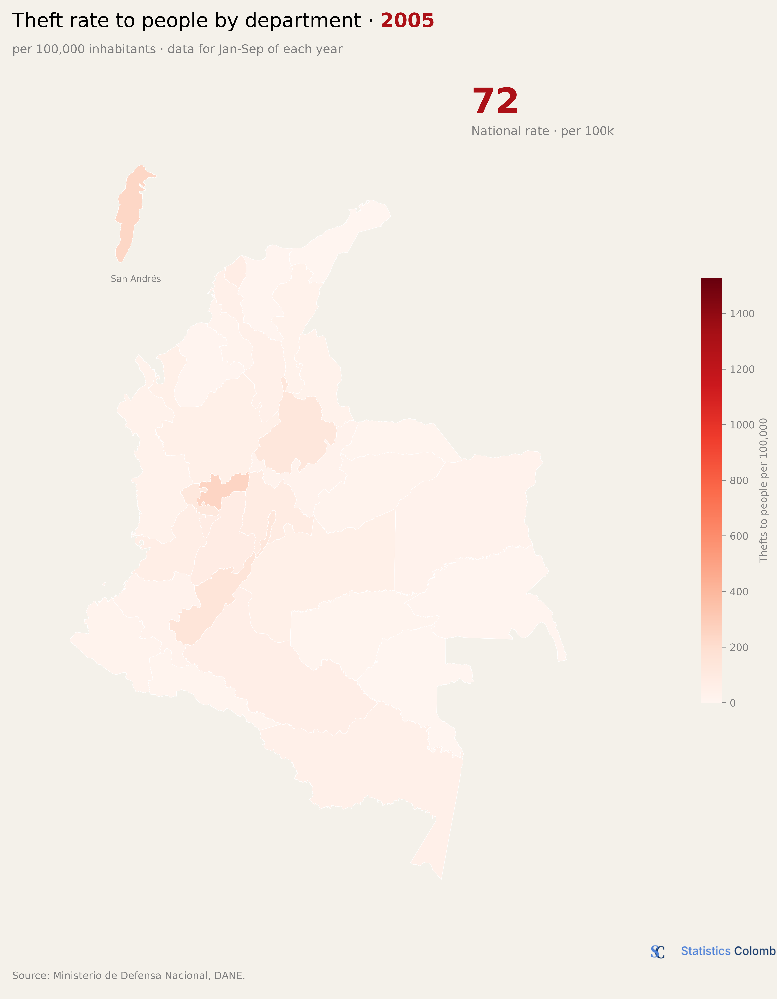

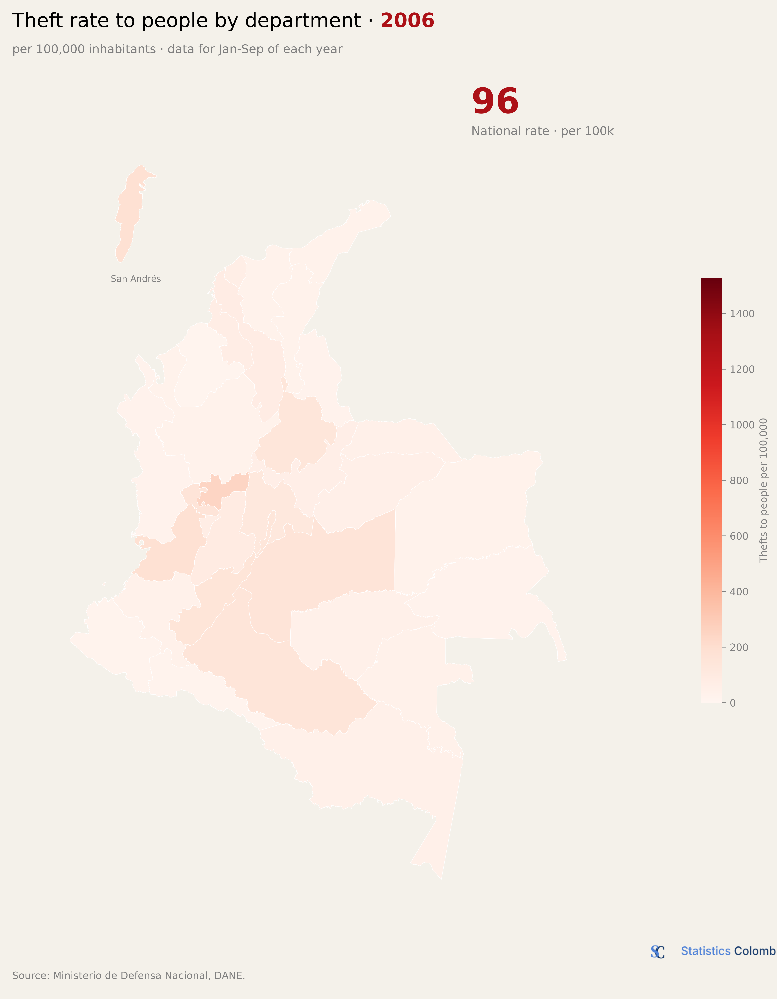

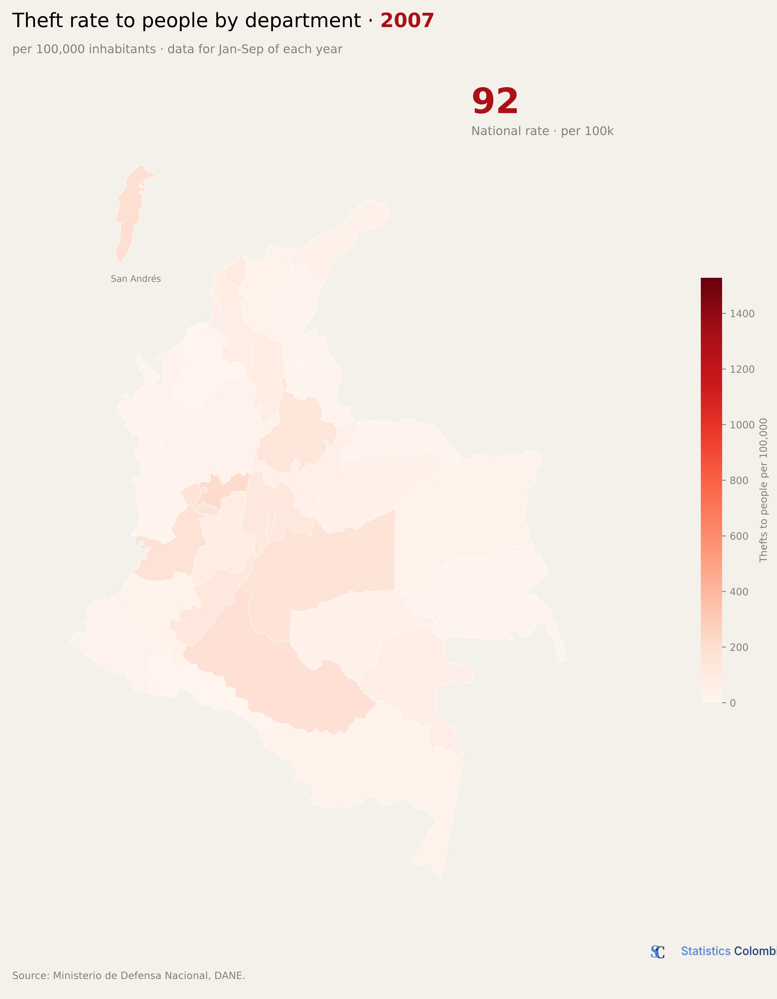

...

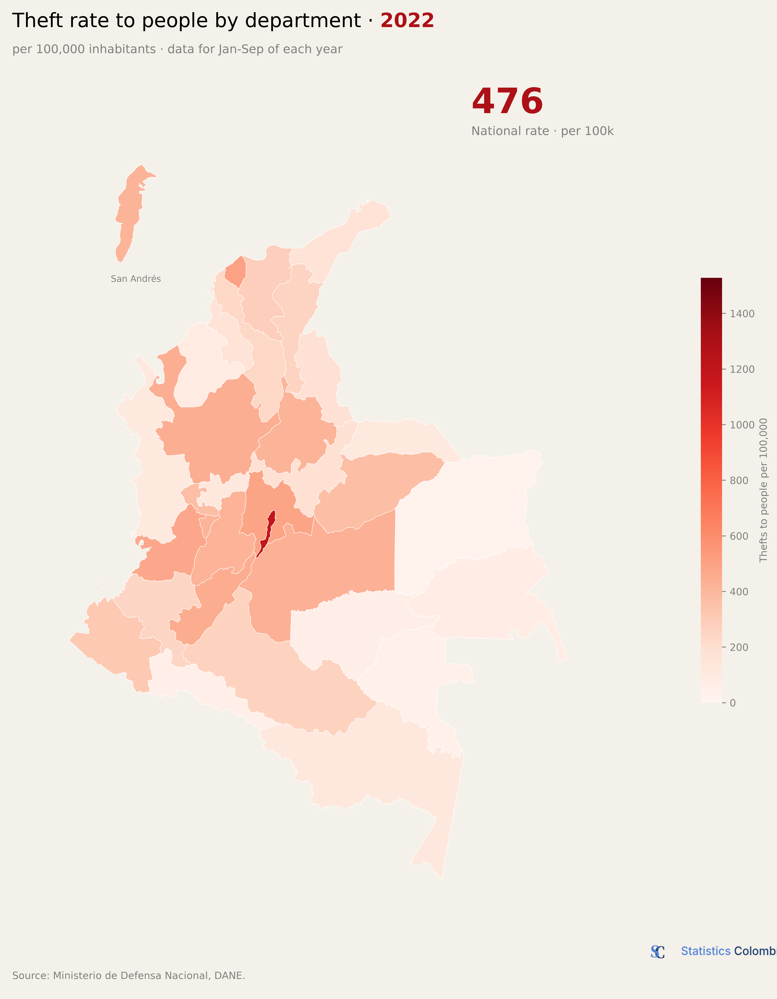

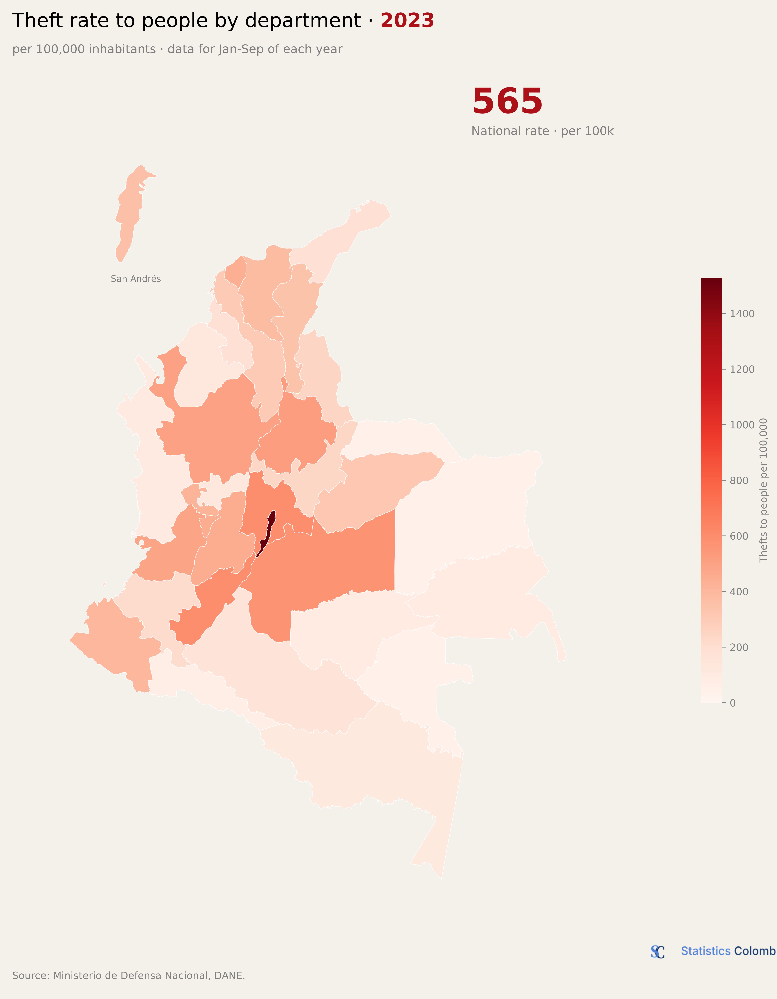

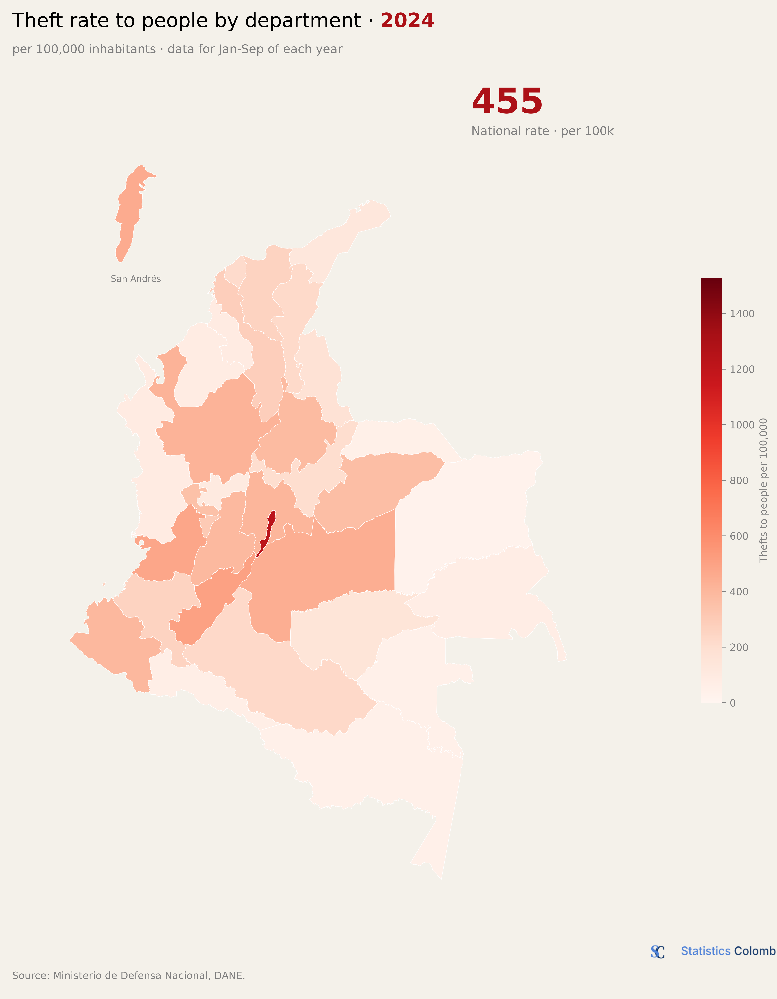

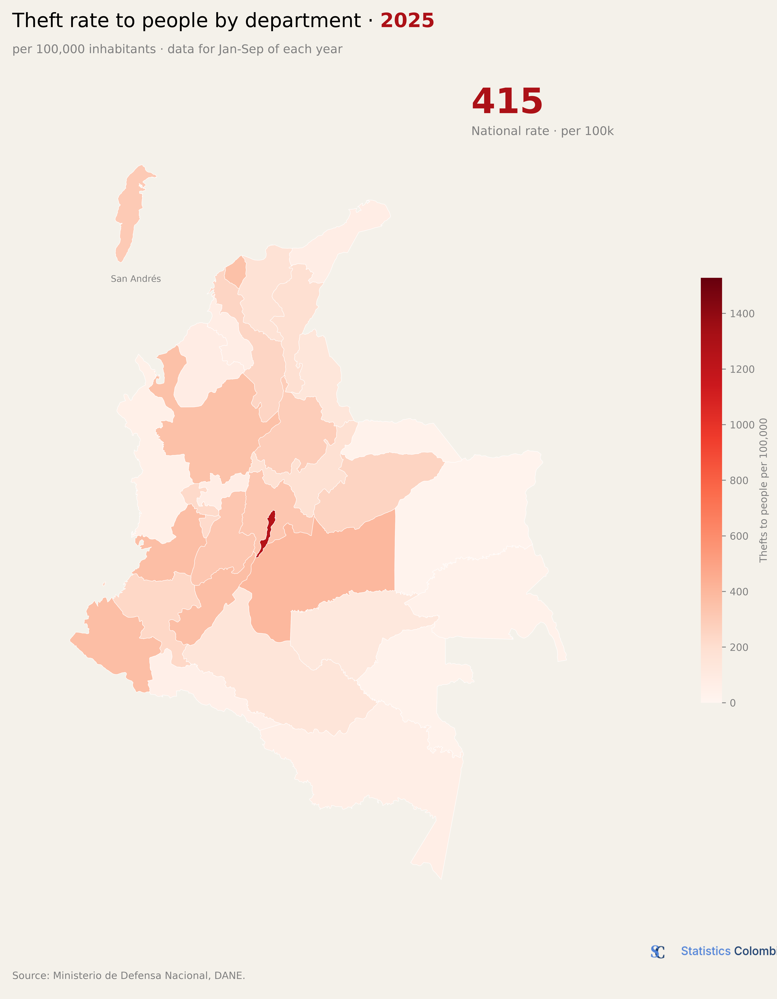

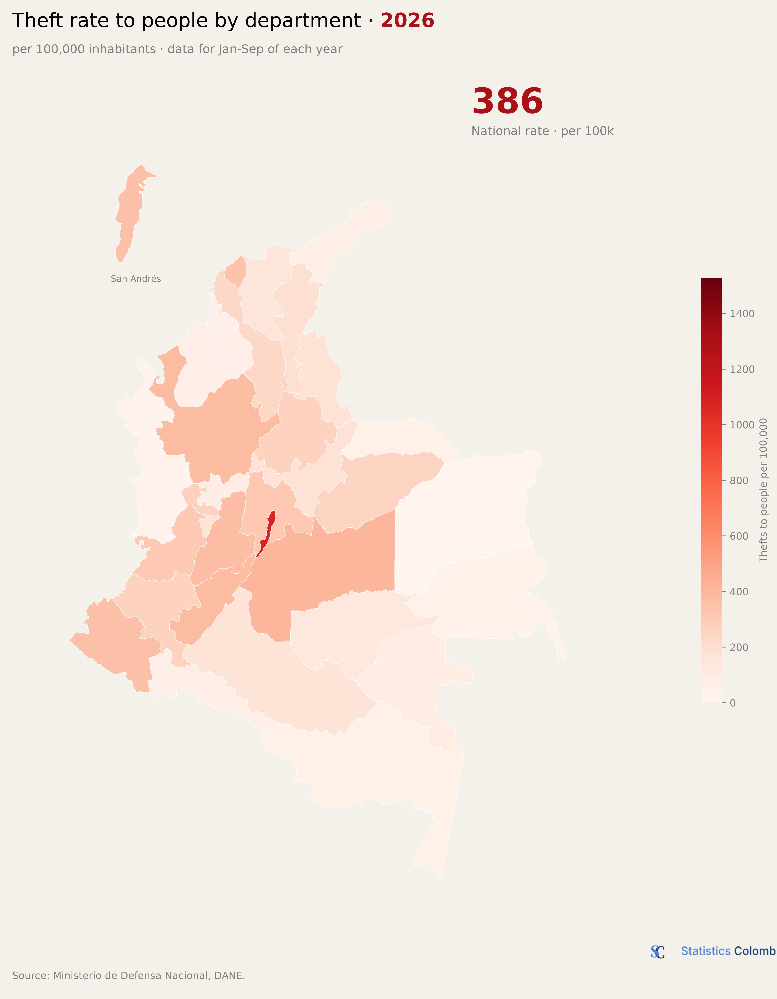

In [10]:
for year in years:
    plot_rate_map(dept_rates[year], national_rates[year], year)